In [1]:
%pip install -q "diffusers==0.35.2" "transformers==4.57.1" "huggingface_hub==0.36.0" accelerate safetensors gradio sentencepiece

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 76.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 118.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.1/566.1 kB 47.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 32.3/32.3 MB 72.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.0/60.0 kB 6.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 125.4 MB/s eta 0:00:00


In [5]:
from huggingface_hub import hf_hub_download

model_id = "BAAI/AltDiffusion-m9"

try:
    path = hf_hub_download(
        repo_id=model_id,
        filename="model_index.json"
    )
    print("Model configuration downloaded:", path)

except Exception as e:
    print(type(e).__name__)
    print(str(e))

Model configuration downloaded: /root/.cache/huggingface/hub/models--BAAI--AltDiffusion-m9/snapshots/a5ea9e304bcf00e9d6ca28fbf81032ac31ebf624/model_index.json


In [6]:
import json
from huggingface_hub import hf_hub_download

model_id = "BAAI/AltDiffusion-m9"

config_path = hf_hub_download(
    repo_id=model_id,
    filename="model_index.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))

{
  "_class_name": "AltDiffusionPipeline",
  "_diffusers_version": "0.8.0.dev0",
  "feature_extractor": [
    "transformers",
    "CLIPImageProcessor"
  ],
  "safety_checker": [
    "stable_diffusion",
    "StableDiffusionSafetyChecker"
  ],
  "scheduler": [
    "diffusers",
    "PNDMScheduler"
  ],
  "text_encoder": [
    "alt_diffusion",
    "RobertaSeriesModelWithTransformation"
  ],
  "tokenizer": [
    "transformers",
    "XLMRobertaTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderKL"
  ]
}


In [7]:
import json
from huggingface_hub import hf_hub_download

model_id = "BAAI/AltDiffusion-m9"

config_path = hf_hub_download(
    repo_id=model_id,
    filename="model_index.json"
)

with open(config_path, "r") as f:
    config = json.load(f)

print(json.dumps(config, indent=2))

{
  "_class_name": "AltDiffusionPipeline",
  "_diffusers_version": "0.8.0.dev0",
  "feature_extractor": [
    "transformers",
    "CLIPImageProcessor"
  ],
  "safety_checker": [
    "stable_diffusion",
    "StableDiffusionSafetyChecker"
  ],
  "scheduler": [
    "diffusers",
    "PNDMScheduler"
  ],
  "text_encoder": [
    "alt_diffusion",
    "RobertaSeriesModelWithTransformation"
  ],
  "tokenizer": [
    "transformers",
    "XLMRobertaTokenizer"
  ],
  "unet": [
    "diffusers",
    "UNet2DConditionModel"
  ],
  "vae": [
    "diffusers",
    "AutoencoderKL"
  ]
}


In [9]:
import torch
from diffusers import DiffusionPipeline

model_id = "stabilityai/sd-turbo"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=(
        torch.float16
        if torch.cuda.is_available()
        else torch.float32
    )
)

if torch.cuda.is_available():
    pipe = pipe.to("cuda")

print("Model loaded successfully!")

model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

special_tokens_map.json:   0%|          | 0.00/574 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/618 [00:00<?, ?B/s]

...

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.46G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!
You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Model loaded successfully!


  0%|          | 0/4 [00:00<?, ?it/s]

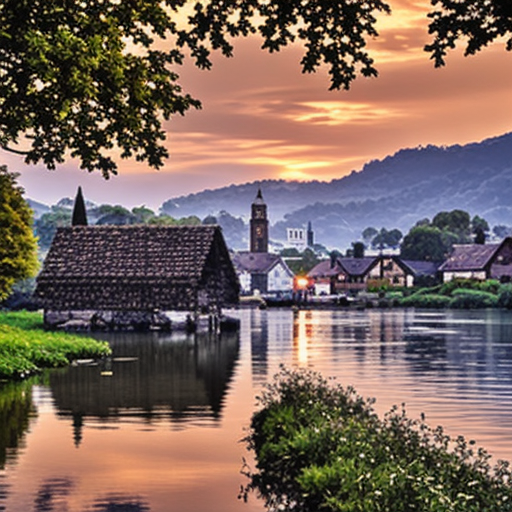

In [10]:
prompt = "A beautiful village at sunrise, realistic photography"

result = pipe(
    prompt=prompt,
    num_inference_steps=4,
    guidance_scale=0.0,
    height=512,
    width=512
)

display(result.images[0])

In [11]:
%pip install -q gradio transformers sentencepiece deep-translator diffusers accelerate safetensors

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.3/42.3 kB 4.9 MB/s eta 0:00:00


In [12]:
from transformers import pipeline

translator = pipeline(
    "translation",
    model="Helsinki-NLP/opus-mt-mul-en"
)

print("Translation model loaded!")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/310M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/310M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/707k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/791k [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:175: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")
Device set to use cuda:0


Translation model loaded!


In [13]:
import torch
from diffusers import DiffusionPipeline

model_id = "stabilityai/sd-turbo"

pipe = DiffusionPipeline.from_pretrained(
    model_id,
    torch_dtype=(
        torch.float16
        if torch.cuda.is_available()
        else torch.float32
    )
)

if torch.cuda.is_available():
    pipe = pipe.to("cuda")

print("Image model loaded!")

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion.StableDiffusionPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Image model loaded!


In [14]:
import gradio as gr

def generate_image(prompt):
    if not prompt or not prompt.strip():
        raise gr.Error("Please enter a prompt.")

    try:
        translated = translator(
            prompt.strip(),
            max_length=128
        )[0]["translation_text"]

        result = pipe(
            prompt=translated,
            num_inference_steps=4,
            guidance_scale=0.0,
            height=512,
            width=512
        )

        return result.images[0], translated

    except Exception as e:
        raise gr.Error(f"{type(e).__name__}: {e}")

app = gr.Interface(
    fn=generate_image,
    inputs=gr.Textbox(
        label="Enter a prompt in any language",
        placeholder="உதய சூரியனுடன் அழகான கிராமம்"
    ),
    outputs=[
        gr.Image(label="Generated Image"),
        gr.Textbox(label="English translation")
    ],
    title="Multilingual Text-to-Image AI",
    description="Enter a prompt in a supported language and generate an image."
)

app.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f0a16f3ddb2ba081fa.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [15]:
import torch
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

translation_id = "facebook/nllb-200-distilled-600M"

device = "cuda" if torch.cuda.is_available() else "cpu"

translator_tokenizer = AutoTokenizer.from_pretrained(
    translation_id
)

translator_model = AutoModelForSeq2SeqLM.from_pretrained(
    translation_id,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)

print("Multilingual translator loaded!")


tokenizer_config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/4.85M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/17.3M [00:00<?, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/846 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


pytorch_model.bin:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/2.46G [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/189 [00:00<?, ?B/s]

Multilingual translator loaded!


In [16]:
def translate_to_english(text, source_language):
    translator_tokenizer.src_lang = source_language

    inputs = translator_tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=256
    ).to(device)

    translated_tokens = translator_model.generate(
        **inputs,
        forced_bos_token_id=translator_tokenizer.convert_tokens_to_ids(
            "eng_Latn"
        ),
        max_new_tokens=128
    )

    return translator_tokenizer.batch_decode(
        translated_tokens,
        skip_special_tokens=True
    )[0]


test = translate_to_english(
    "சூரிய உதயத்தில் அழகான கிராமம்",
    "tam_Taml"
)

print("English translation:", test)

English translation: The beautiful village at sunrise


In [22]:

import gradio as gr

LANGUAGES = {
    "Tamil": "tam_Taml",
    "Hindi": "hin_Deva",
    "English": "eng_Latn",
    "Spanish": "spa_Latn",
    "French": "fra_Latn",
    "Chinese (Simplified)": "zho_Hans",
    "Japanese": "jpn_Jpan",
    "Korean": "kor_Hang",
    "Arabic": "arb_Arab",
    "Russian": "rus_Cyrl",
    "Italian": "ita_Latn"
}

def generate_multilingual_image(prompt, language):
    if not prompt or not prompt.strip():
        raise gr.Error("Please enter a prompt!")

    try:
        english_prompt = translate_to_english(
            prompt.strip(),
            LANGUAGES[language]
        )

        result = pipe(
            prompt=english_prompt,
            num_inference_steps=4,
            guidance_scale=0.0,
            height=512,
            width=512
        )

        return result.images[0], english_prompt

    except Exception as e:
        raise gr.Error(f"{type(e).__name__}: {e}")


custom_css = """
.gradio-container {
    background: linear-gradient(135deg, #13072e, #3f2182, #087e8b) !important;
}
#jad-title {
    text-align: center;
    background: linear-gradient(90deg, #ff4ecd, #ffd166, #00e5ff);
    color: #160d35;
    padding: 24px;
    border-radius: 22px;
    margin-bottom: 16px;
}
#jad-title h1 {
    font-size: 52px;
    font-weight: 900;
    letter-spacing: 8px;
}
#jad-title p {
    font-size: 17px;
    font-weight: 600;
}
.jad-panel {
    border: 2px solid #c77dff !important;
    border-radius: 18px !important;
    background: rgba(25, 15, 55, 0.9) !important;
}
button.primary {
    background: linear-gradient(90deg, #ff4ecd, #7b2ff7) !important;
    color: white !important;
    border: none !important;
    font-weight: bold !important;
}
"""

with gr.Blocks(
    theme=gr.themes.Soft(
        primary_hue="purple",
        secondary_hue="pink",
        neutral_hue="slate"
    ),
    css=custom_css,
    title="JAD - AI Image Converter"
) as app:

    gr.HTML("""
    <div id="jad-title">
        <h1>JAD ✨</h1>
        <p>🌈 MULTILINGUAL TEXT-TO-IMAGE AI GENERATOR 🌈</p>
        <p>Turn your words into colourful imagination!</p>
    </div>
    """)

    with gr.Row():
        with gr.Column(elem_classes=["jad-panel"]):
            prompt = gr.Textbox(
                label="✍️ Describe your imagination",
                placeholder="Example: A beautiful village at sunrise",
                lines=4
            )

            language = gr.Dropdown(
                choices=list(LANGUAGES.keys()),
                value="Tamil",
                label="🌍 Select your language"
            )

            generate_btn = gr.Button(
                "✨ GENERATE IMAGE",
                variant="primary",
                size="lg"
            )

            english_output = gr.Textbox(
                label="🔤 English prompt used by AI",
                interactive=False
            )

        with gr.Column(elem_classes=["jad-panel"]):
            image_output = gr.Image(
                label="🎨 Your AI Creation",
                type="pil"
            )

    generate_btn.click(
        fn=generate_multilingual_image,
        inputs=[prompt, language],
        outputs=[image_output, english_output]
    )



app.launch(share=True)


/tmp/ipykernel_930/4041666756.py:75: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme, css. Please pass these parameters to launch() instead.
  with gr.Blocks(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://f02f23d9e60bc0583a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [19]:
prompt = "A cute, colorful Pikachu standing in a vibrant rainbow-themed background, bright yellow fur, glowing red cheeks, electric sparks, beautiful blue and purple lighting, and the name 'JAD' written clearly in large, colorful letters. High-quality 3D cartoon art, vibrant colors, sharp details."